# Etapa 2: Relatii intre features si Feature Engineering

Acest notebook continua analiza din `EDA.ipynb` (Etapa 1) si porneste de la datele curatate salvate acolo in `df.csv`
(valori lipsa tratate, `Has_Garage` adaugat). Aici raspundem la doua cerinte din tema:

1. **Conexiuni intre features** - 4 grafice, fiecare construit in jurul unei intrebari diferite:
   - heatmap de corelatii (*care features numerice sunt legate de pret si care sunt redundante intre ele?*)
   - scatter plots vs. `SalePrice` (*ce forma are relatia: liniara, curbata, cu dispersie crescanda?*)
   - violin plot pe variabile categorice (*cum difera distributia pretului intre categorii, nu doar media?*)
   - bar plot cu `groupby` (*care categorii valoreaza mai mult si cat de mare e diferenta?*)
2. **Features noi din combinatii** ale coloanelor existente, cu justificare economica si statistica,
   salvate in `df_fe.csv` pentru etapele urmatoare.

> **Nota tehnica.** `pd.read_csv` interpreteaza implicit textul `None` ca valoare lipsa (NaN). Pentru ca in Etapa 1 am folosit
> `'None'` cu sensul "facilitatea nu exista", citim fisierul cu `keep_default_na=False` si tratam ca NaN doar celulele goale.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140)

# Datele curatate din Etapa 1 (EDA.ipynb). 'None' trebuie pastrat ca text, nu citit ca NaN.
df = pd.read_csv("df.csv", keep_default_na=False, na_values=[""])

# Coloane numerice ca tip, dar categorii ca sens (la fel ca in Etapa 1)
for col in ["MS SubClass", "Mo Sold"]:
    df[col] = df[col].astype(str)

id_cols = ["Order", "PID"]
numeric_features = [c for c in df.select_dtypes(include=[np.number]).columns if c not in id_cols]
categorical_features = list(df.select_dtypes(exclude=[np.number]).columns)

print(f"Randuri: {df.shape[0]} | Coloane: {df.shape[1]}")
print(f"Numerice: {len(numeric_features)} | Categorice: {len(categorical_features)}")
print(f"Valori lipsa ramase: {df.isna().sum().sum()}")

Randuri: 2930 | Coloane: 83
Numerice: 36 | Categorice: 45
Valori lipsa ramase: 0


## Graficul 1 - Heatmap de corelatii

**Intrebarea:** *Care features numerice sunt cel mai puternic legate de `SalePrice` si care dintre ele sunt redundante
(masoara acelasi lucru)?*

Calculam corelatia Pearson a fiecarui feature numeric cu `SalePrice`, pastram primele 15 dupa valoarea absoluta si desenam
matricea de corelatii pentru acest subset (o matrice completa 36 x 36 ar fi ilizibila). Comparam si cu `log(SalePrice)`,
pentru ca Etapa 1 a aratat ca pretul este puternic asimetric spre dreapta.

In [2]:
df["SalePrice_log"] = np.log(df["SalePrice"])

corr_price = df[numeric_features].corr()["SalePrice"].drop("SalePrice")
corr_log = df[numeric_features + ["SalePrice_log"]].corr()["SalePrice_log"].drop(["SalePrice", "SalePrice_log"])

corr_table = pd.DataFrame({"corr_SalePrice": corr_price, "corr_logSalePrice": corr_log})
corr_table["abs"] = corr_table["corr_SalePrice"].abs()
corr_table = corr_table.sort_values("abs", ascending=False).drop(columns="abs")

print("Top 15 features dupa |corelatia| cu SalePrice:")
print(corr_table.head(15).round(3))
print("\nCele mai slabe 5 corelatii cu SalePrice:")
print(corr_table.tail(5).round(3))

top_features = corr_table.head(15).index.tolist()

Top 15 features dupa |corelatia| cu SalePrice:
                corr_SalePrice  corr_logSalePrice
Overall Qual             0.799              0.826
Gr Liv Area              0.707              0.696
Garage Cars              0.648              0.675
Garage Area              0.640              0.651
Total Bsmt SF            0.633              0.626
1st Flr SF               0.622              0.603
Year Built               0.558              0.615
Full Bath                0.546              0.577
Garage Yr Blt            0.544              0.601
Year Remod/Add           0.533              0.586
Mas Vnr Area             0.502              0.443
TotRms AbvGrd            0.495              0.493
Fireplaces               0.475              0.489
BsmtFin SF 1             0.433              0.411
Lot Frontage             0.353              0.347

Cele mai slabe 5 corelatii cu SalePrice:
                corr_SalePrice  corr_logSalePrice
Bsmt Half Bath          -0.036             -0.021
3Ssn Porch 

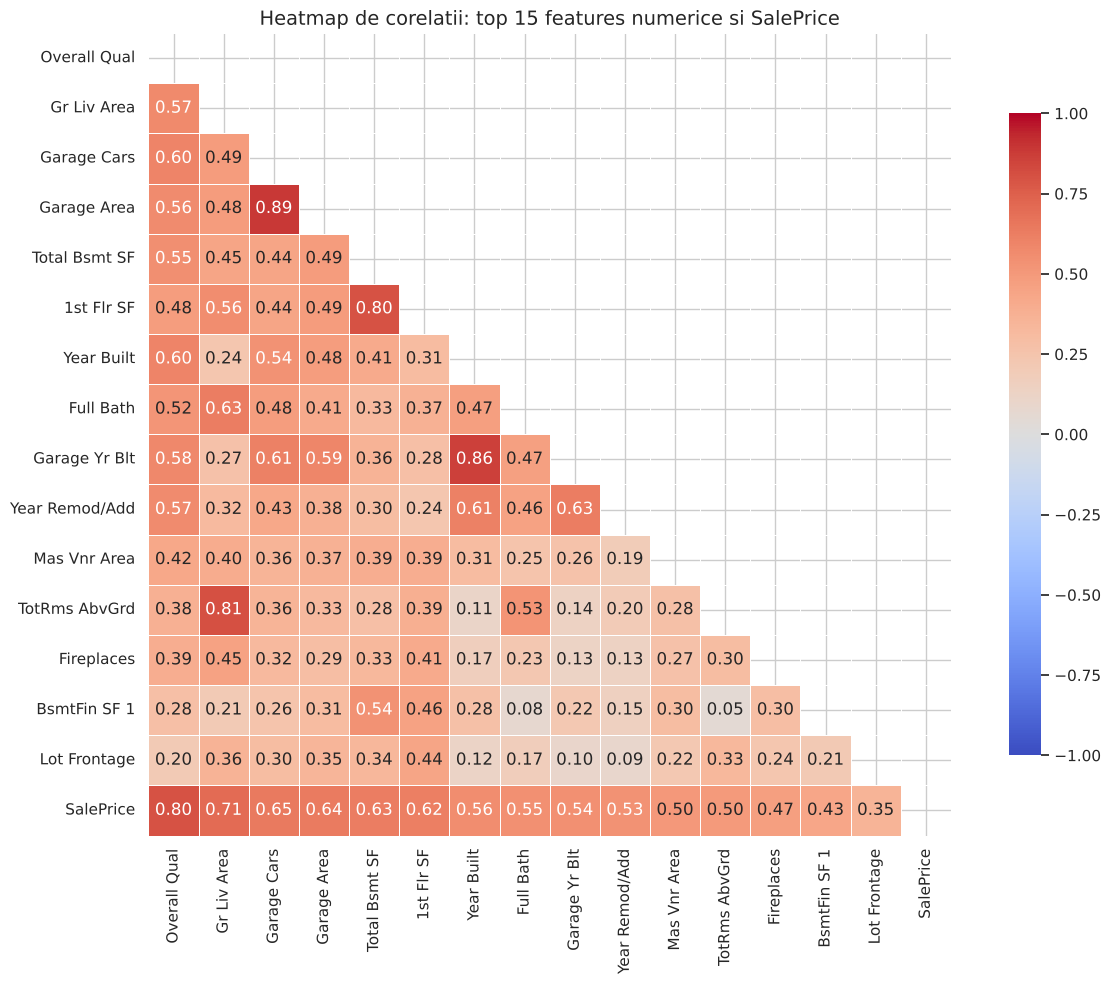

Perechi de features cu |r| > 0.6 (posibila redundanta):
     feature_1     feature_2     r
   Garage Area   Garage Cars 0.890
 Garage Yr Blt    Year Built 0.861
 TotRms AbvGrd   Gr Liv Area 0.808
    1st Flr SF Total Bsmt SF 0.800
     Full Bath   Gr Liv Area 0.630
Year Remod/Add Garage Yr Blt 0.626
 Garage Yr Blt   Garage Cars 0.613
Year Remod/Add    Year Built 0.612


In [3]:
corr_matrix = df[top_features + ["SalePrice"]].corr()

mask = np.triu(np.ones_like(corr_matrix, dtype=bool))  # ascundem triunghiul superior (e simetric)
plt.figure(figsize=(13, 10))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            center=0, square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Heatmap de corelatii: top 15 features numerice si SalePrice", fontsize=14)
plt.tight_layout()
plt.show()

# Perechi de features puternic corelate intre ele (candidate la redundanta)
pairs = (corr_matrix.where(~mask).stack().reset_index())
pairs.columns = ["feature_1", "feature_2", "r"]
pairs = pairs[(pairs["feature_1"] != "SalePrice") & (pairs["feature_2"] != "SalePrice")]
print("Perechi de features cu |r| > 0.6 (posibila redundanta):")
print(pairs[pairs["r"].abs() > 0.6].sort_values("r", ascending=False).round(3).to_string(index=False))

### Interpretare - heatmap

*(schita cu valorile reale din rulare - de rescris de Carmen cu cuvintele ei)*

- Cele mai puternice corelatii cu pretul: `Overall Qual` (r = 0.80), `Gr Liv Area` (0.71), `Garage Cars` (0.65),
  `Garage Area` (0.64), `Total Bsmt SF` (0.63), `1st Flr SF` (0.62), `Year Built` (0.56). Deci pretul este determinat in
  principal de **calitate**, **suprafata** si **garaj**, apoi de **vechime**.
- Cu `log(SalePrice)` corelatiile cresc pentru calitate si vechime (`Overall Qual` 0.80 -> 0.83, `Year Built` 0.56 -> 0.62,
  `Garage Yr Blt` 0.54 -> 0.60) si raman practic la fel pentru suprafete -> inca un argument pentru a prezice pretul
  logaritmat la L2.
- Corelatii practic nule: `Yr Sold`, `Mo Sold` (nu apar), `Misc Val`, `BsmtFin SF 2`, `3Ssn Porch`, `Bsmt Half Bath` ->
  candidate la eliminare (anul vanzarii nu conteaza pentru ca 2006-2010 au preturi stabile in Ames).
- Perechi redundante (masoara acelasi lucru): `Garage Cars` ~ `Garage Area` (r = 0.89), `Gr Liv Area` ~ `TotRms AbvGrd` (0.81),
  `Total Bsmt SF` ~ `1st Flr SF` (0.80). Intr-un model liniar nu e nevoie de ambele din fiecare pereche.
- `Year Built` ~ `Garage Yr Blt` (r = 0.86) este si un exemplu bun de corelatie **fara cauzalitate directa**: garajul nu
  "imbatraneste" casa, ambele sunt determinate de acelasi eveniment (constructia).

## Graficul 2 - Scatter plots vs. SalePrice

**Intrebarea:** *Ce forma are relatia dintre cele mai importante features numerice si pret - este liniara, curbata, iar
dispersia creste odata cu marimea casei? Exista observatii care ies din tipar?*

Coloram punctele dupa `Overall Qual`, ca sa vedem daca a treia variabila explica dispersia.

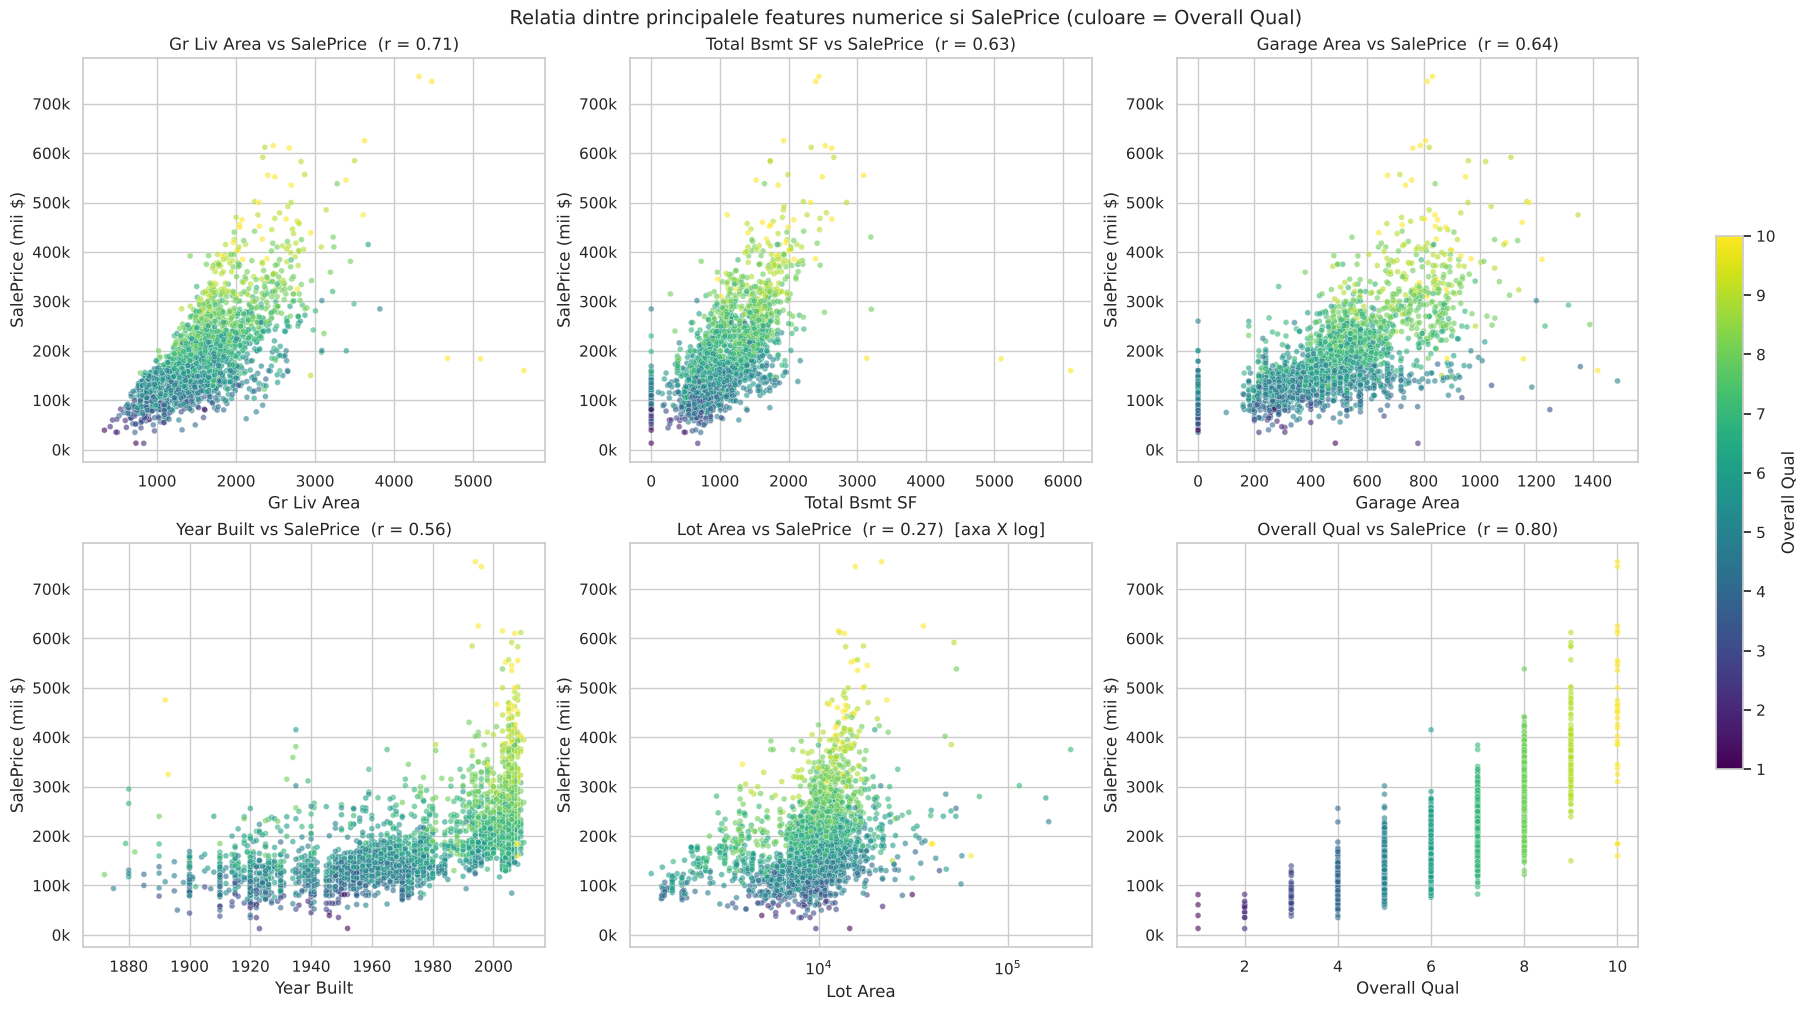

Case cu Gr Liv Area > 4000 sq ft:
 Order  Gr Liv Area  Overall Qual  SalePrice Sale Condition
  1499         5642            10     160000        Partial
  2181         5095            10     183850        Partial
  2182         4676            10     184750        Partial
  1761         4476            10     745000        Abnorml
  1768         4316            10     755000         Normal


In [4]:
scatter_cols = ["Gr Liv Area", "Total Bsmt SF", "Garage Area", "Year Built", "Lot Area", "Overall Qual"]

fig, axes = plt.subplots(2, 3, figsize=(18, 10), constrained_layout=True)
for ax, col in zip(axes.flat, scatter_cols):
    sns.scatterplot(data=df, x=col, y="SalePrice", hue="Overall Qual", palette="viridis",
                    alpha=0.6, s=18, ax=ax, legend=False)
    ax.set_title(f"{col} vs SalePrice  (r = {df[col].corr(df['SalePrice']):.2f})")
    ax.set_ylabel("SalePrice (mii $)")
    ax.yaxis.set_major_formatter(lambda v, p: f"{v / 1000:.0f}k")
axes[1, 1].set_xscale("log")  # Lot Area are o coada foarte lunga
axes[1, 1].set_title(axes[1, 1].get_title() + "  [axa X log]")

# legenda comuna pentru culoare
sm = plt.cm.ScalarMappable(cmap="viridis", norm=plt.Normalize(df["Overall Qual"].min(), df["Overall Qual"].max()))
fig.colorbar(sm, ax=axes, shrink=0.6, label="Overall Qual")
fig.suptitle("Relatia dintre principalele features numerice si SalePrice (culoare = Overall Qual)", fontsize=14)
plt.show()

# Observatii care ies din tipar: case foarte mari vandute ieftin (De Cock recomanda excluderea lor)
suspect = df[df["Gr Liv Area"] > 4000][["Order", "Gr Liv Area", "Overall Qual", "SalePrice", "Sale Condition"]]
print("Case cu Gr Liv Area > 4000 sq ft:")
print(suspect.sort_values("Gr Liv Area", ascending=False).to_string(index=False))

### Interpretare - scatter plots

*(schita cu valorile reale din rulare - de rescris de Carmen cu cuvintele ei)*

- `Gr Liv Area` (r = 0.71) si `Total Bsmt SF` (0.63): relatie aproximativ liniara, dar cu **dispersie crescanda** la suprafete
  mari (heteroscedasticitate) -> inca un motiv pentru `log(SalePrice)`.
- Culoarea arata ca, la aceeasi suprafata, casele cu `Overall Qual` mare sunt sistematic mai scumpe: calitatea si marimea
  actioneaza impreuna (sugereaza un feature de interactiune, vezi `QualxLivArea` in sectiunea de feature engineering).
- `Year Built`: relatie **neliniara** - pentru casele de dinainte de 1950 anul practic nu conteaza (r = -0.02), pentru cele
  de dupa 1950 corelatia este puternica (r = 0.57); pretul "decoleaza" la constructiile din anii 1990-2010.
- `Lot Area`: corelatie slaba (r = 0.27, 0.37 pe scara log); loturile uriase nu inseamna case scumpe (teren la periferie).
- `Garage Area` (0.64): relatie liniara clara, cu un grup de case fara garaj la 0.
- Cele 5 case cu `Gr Liv Area` > 4000 sq ft: trei sunt vanzari **partiale** (`Sale Condition = Partial`) la 160-185k - case
  uriase de calitate 10 vandute la pret de casa medie, exact outlierii pe care autorul datasetului (De Cock) recomanda sa-i
  excludem; celelalte doua (745k, 755k) sunt reale. In Etapa 1 s-a mentionat eliminarea lor, dar `df.csv` le contine inca -
  de clarificat in echipa.

## Graficul 3 - Violin plot pe variabile categorice

**Intrebarea:** *Cum difera intreaga distributie a pretului (nu doar media) intre categoriile unei variabile calitative?
Categoriile sunt bine separate sau se suprapun?*

Alegem o variabila **ordinala** (`Kitchen Qual`: Po < Fa < TA < Gd < Ex) si una **nominala** (`Bldg Type`).

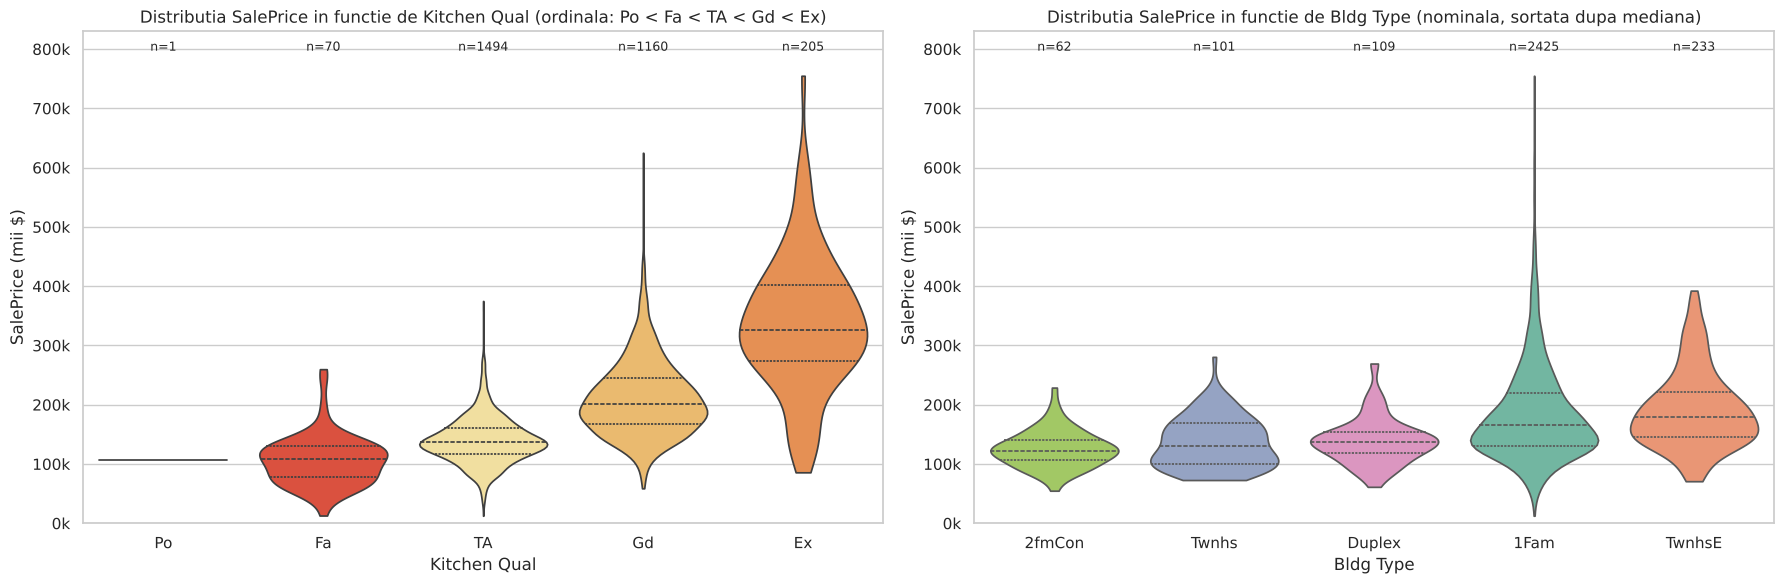

              count    median      mean       std
Kitchen Qual                                     
Po                1  107500.0  107500.0       NaN
Fa               70  107750.0  105907.0   41975.0
TA             1494  136500.0  139550.0   38448.0
Gd             1160  201000.0  210836.0   63585.0
Ex              205  325624.0  337339.0  114361.0

           count    median      mean      std
Bldg Type                                    
2fmCon        62  122250.0  125582.0  31089.0
Twnhs        101  130000.0  135934.0  41939.0
Duplex       109  136905.0  139809.0  39499.0
1Fam        2425  165000.0  184812.0  82822.0
TwnhsE       233  180000.0  192312.0  66192.0


In [5]:
qual_order = ["Po", "Fa", "TA", "Gd", "Ex"]
qual_order = [q for q in qual_order if q in df["Kitchen Qual"].unique()]

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
y_top = df["SalePrice"].max() * 1.10  # loc deasupra viorilor pentru eticheta n=

sns.violinplot(data=df, x="Kitchen Qual", y="SalePrice", order=qual_order, hue="Kitchen Qual",
               palette="YlOrRd", inner="quartile", cut=0, legend=False, ax=axes[0])
axes[0].set_title("Distributia SalePrice in functie de Kitchen Qual (ordinala: Po < Fa < TA < Gd < Ex)")
for i, q in enumerate(qual_order):
    n = (df["Kitchen Qual"] == q).sum()
    axes[0].text(i, y_top * 0.96, f"n={n}", ha="center", fontsize=9)

bt_order = df.groupby("Bldg Type")["SalePrice"].median().sort_values().index
sns.violinplot(data=df, x="Bldg Type", y="SalePrice", order=bt_order, hue="Bldg Type",
               palette="Set2", inner="quartile", cut=0, legend=False, ax=axes[1])
axes[1].set_title("Distributia SalePrice in functie de Bldg Type (nominala, sortata dupa mediana)")
for i, b in enumerate(bt_order):
    n = (df["Bldg Type"] == b).sum()
    axes[1].text(i, y_top * 0.96, f"n={n}", ha="center", fontsize=9)

for ax in axes:
    ax.set_ylim(0, y_top)
    ax.set_ylabel("SalePrice (mii $)")
    ax.yaxis.set_major_formatter(lambda v, p: f"{v / 1000:.0f}k")
plt.tight_layout()
plt.show()

print(df.groupby("Kitchen Qual")["SalePrice"].agg(["count", "median", "mean", "std"]).reindex(qual_order).round(0))
print()
print(df.groupby("Bldg Type")["SalePrice"].agg(["count", "median", "mean", "std"]).loc[bt_order].round(0))

### Interpretare - violin plots

*(schita cu valorile reale din rulare - de rescris de Carmen cu cuvintele ei)*

- `Kitchen Qual`: medianele cresc monoton Fa 108k -> TA 137k -> Gd 201k -> Ex 326k, iar distributiile se **largesc** odata
  cu calitatea (deviatia standard creste de la 42k la 114k; bucatariile Ex apar in case intre ~185k si ~475k). `Po` are o
  singura casa, deci "vioara" lui nu inseamna nimic statistic. Fa si TA se suprapun mult - diferenta reala apare de la Gd in sus.
- `Bldg Type`: surprinzator, `TwnhsE` (townhouse de capat) are mediana cea mai mare (180k), peste casele unifamiliale `1Fam`
  (165k) - pentru ca sunt concentrate in cartiere noi si scumpe (Somerst, NridgHt, StoneBr). In schimb `1Fam` are coada lunga
  spre 400-750k, pe care niciun alt tip nu o are. `2fmCon`, `Twnhs` si `Duplex` sunt comprimate in zona 120-140k.
- Concluzie: variabila **ordinala** de calitate separa preturile mult mai clar decat tipul cladirii (**nominal**), unde
  categoriile se suprapun puternic; violin plot-ul arata forma si cozile distributiei, pe care o medie simpla le-ar ascunde.

## Graficul 4 - Bar plot cu `groupby`

**Intrebarea:** *Care cartiere (`Neighborhood`) sunt cele mai scumpe si cele mai ieftine, cat de mare este diferenta
si pe cate vanzari se bazeaza fiecare valoare?*

Folosim **mediana** (robusta la outlieri) si afisam numarul de case pe cartier, ca sa nu tragem concluzii din 2-3 vanzari.

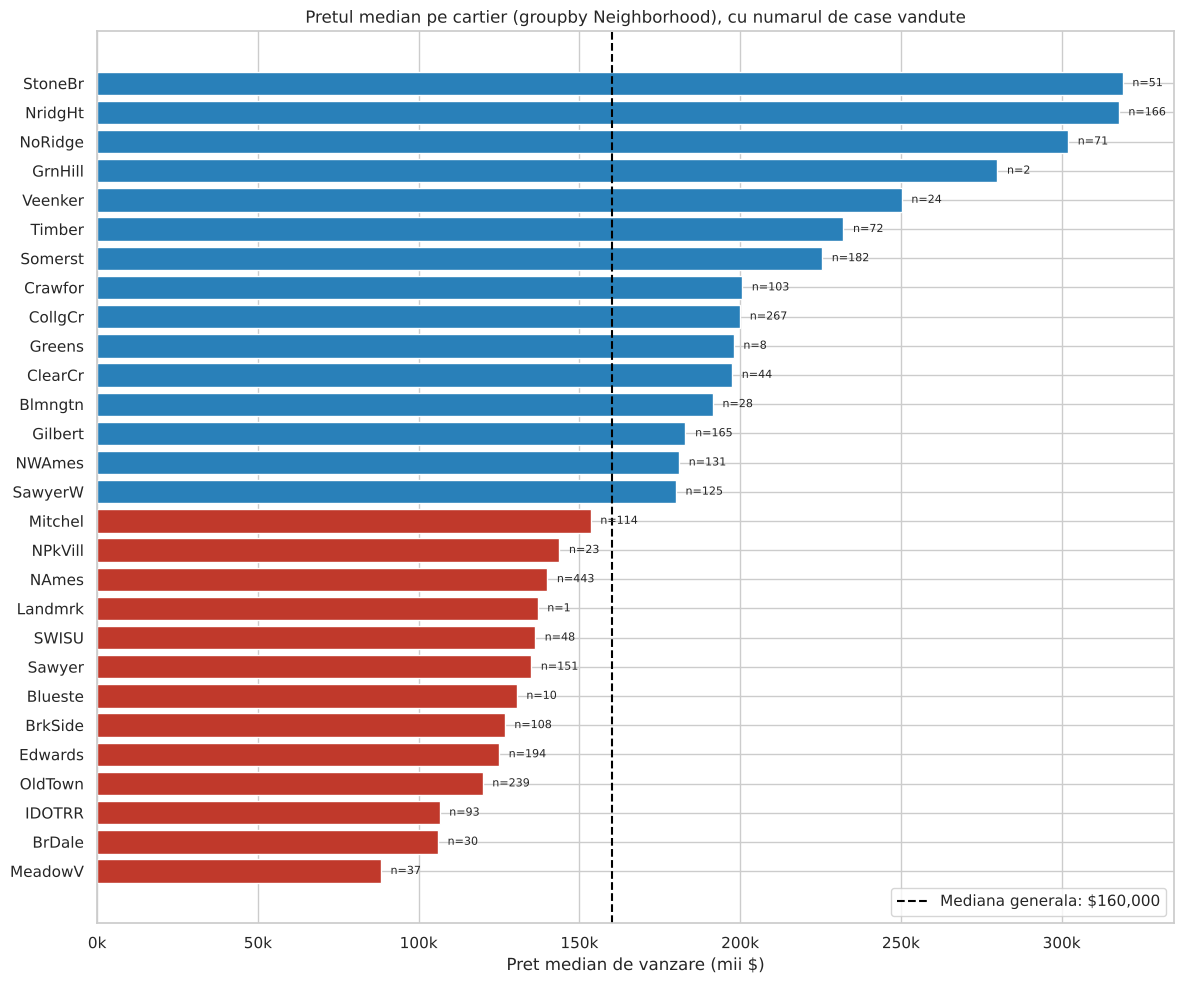

Top 5 cartiere scumpe:
                median      mean  count
Neighborhood                           
StoneBr       319000.0  324229.0     51
NridgHt       317750.0  322018.0    166
NoRidge       302000.0  330319.0     71
GrnHill       280000.0  280000.0      2
Veenker       250250.0  248315.0     24

Top 5 cartiere ieftine:
                median      mean  count
Neighborhood                           
MeadowV        88250.0   95756.0     37
BrDale        106000.0  105608.0     30
IDOTRR        106500.0  103753.0     93
OldTown       119900.0  123992.0    239
Edwards       125000.0  130843.0    194

Raport mediana max / min: 3.6x


In [6]:
nb_stats = (df.groupby("Neighborhood")["SalePrice"]
              .agg(median="median", mean="mean", count="count")
              .sort_values("median", ascending=True))
global_median = df["SalePrice"].median()

plt.figure(figsize=(12, 10))
colors = ["#c0392b" if m < global_median else "#2980b9" for m in nb_stats["median"]]
bars = plt.barh(nb_stats.index, nb_stats["median"], color=colors)
plt.axvline(global_median, color="black", linestyle="--", label=f"Mediana generala: ${global_median:,.0f}")
for bar, n in zip(bars, nb_stats["count"]):
    plt.text(bar.get_width() + 3000, bar.get_y() + bar.get_height() / 2, f"n={n}", va="center", fontsize=8)
plt.gca().xaxis.set_major_formatter(lambda v, p: f"{v / 1000:.0f}k")
plt.xlabel("Pret median de vanzare (mii $)")
plt.title("Pretul median pe cartier (groupby Neighborhood), cu numarul de case vandute")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

print("Top 5 cartiere scumpe:")
print(nb_stats.tail(5)[::-1].round(0))
print("\nTop 5 cartiere ieftine:")
print(nb_stats.head(5).round(0))
print(f"\nRaport mediana max / min: {nb_stats['median'].max() / nb_stats['median'].min():.1f}x")

### Interpretare - bar plot pe cartiere

*(schita cu valorile reale din rulare - de rescris de Carmen cu cuvintele ei)*

- Cartierele cele mai scumpe - StoneBr (319k), NridgHt (318k), NoRidge (302k) - au mediana de **3.6x** fata de cele mai
  ieftine - MeadowV (88k), BrDale (106k), IDOTRR (107k). Locatia este deci unul dintre cei mai puternici factori de pret,
  desi nu apare in heatmap pentru ca e variabila categorica.
- Cateva cartiere au foarte putine vanzari (`Landmrk` 1, `GrnHill` 2, `Greens` 8) -> medianele lor nu sunt de incredere
  (GrnHill pare "al 4-lea cel mai scump" pe baza a doua case); la modelare ar trebui grupate cu cartiere similare.
- Cartierele mari si ieftine (OldTown 239 case, Edwards 194) sunt zonele vechi ale orasului - se leaga de relatia cu `Year Built`.
- `Neighborhood` are 28 de categorii: la L2 one-hot encoding ar produce 28 de coloane; o alternativa este **target encoding**
  (inlocuirea cartierului cu pretul sau median), calculata **doar pe datele de antrenare** ca sa evitam data leakage.

## Feature engineering - features noi din combinatii

**Principiu:** un feature nou merita pastrat daca (1) are un **sens economic** clar - raspunde la o intrebare pe care si-o pune
un cumparator - si (2) aduce **informatie** in plus fata de componentele sale (corelatie mai mare cu pretul sau o relatie mai simpla).

| Feature nou | Formula | Intrebarea cumparatorului |
|---|---|---|
| `TotalSF` | `Total Bsmt SF + 1st Flr SF + 2nd Flr SF` | Cat spatiu total are casa, indiferent cum e impartit pe niveluri? |
| `HouseAge` | `Yr Sold - Year Built` | Cat de veche era casa **la momentul vanzarii**? (anul brut nu spune asta) |
| `YearsSinceRemod` | `Yr Sold - Year Remod/Add` | De cand nu a mai fost renovata? |
| `Remodeled` | `Year Remod/Add != Year Built` | A fost renovata vreodata? |
| `TotalBath` | `Full Bath + 0.5*Half Bath + Bsmt Full Bath + 0.5*Bsmt Half Bath` | Cate bai are casa in total (o baie de serviciu = jumatate)? |
| `TotalPorchSF` | `Wood Deck + Open Porch + Enclosed Porch + 3Ssn Porch + Screen Porch` | Cat spatiu exterior amenajat exista? |
| `HasPool`, `HasFireplace`, `Has2ndFlr`, `HasBsmt` | indicator 0/1 | Exista dotarea? (completeaza `Has_Garage` din Etapa 1) |
| `QualxLivArea` | `Overall Qual * Gr Liv Area` | "Metri patrati de calitate": o casa mare **si** buna valoreaza disproportionat mai mult |
| `LivAreaPerRoom` | `Gr Liv Area / TotRms AbvGrd` | Camerele sunt spatioase sau inghesuite? |

In [7]:
df_fe = df.copy()

df_fe["TotalSF"] = df_fe["Total Bsmt SF"] + df_fe["1st Flr SF"] + df_fe["2nd Flr SF"]
df_fe["HouseAge"] = df_fe["Yr Sold"] - df_fe["Year Built"]
df_fe["YearsSinceRemod"] = df_fe["Yr Sold"] - df_fe["Year Remod/Add"]
df_fe["Remodeled"] = (df_fe["Year Remod/Add"] != df_fe["Year Built"]).astype(int)
df_fe["TotalBath"] = (df_fe["Full Bath"] + 0.5 * df_fe["Half Bath"]
                      + df_fe["Bsmt Full Bath"] + 0.5 * df_fe["Bsmt Half Bath"])
df_fe["TotalPorchSF"] = (df_fe["Wood Deck SF"] + df_fe["Open Porch SF"] + df_fe["Enclosed Porch"]
                         + df_fe["3Ssn Porch"] + df_fe["Screen Porch"])
df_fe["HasPool"] = (df_fe["Pool Area"] > 0).astype(int)
df_fe["HasFireplace"] = (df_fe["Fireplaces"] > 0).astype(int)
df_fe["Has2ndFlr"] = (df_fe["2nd Flr SF"] > 0).astype(int)
df_fe["HasBsmt"] = (df_fe["Total Bsmt SF"] > 0).astype(int)
df_fe["QualxLivArea"] = df_fe["Overall Qual"] * df_fe["Gr Liv Area"]
df_fe["LivAreaPerRoom"] = df_fe["Gr Liv Area"] / df_fe["TotRms AbvGrd"]

new_features = ["TotalSF", "HouseAge", "YearsSinceRemod", "Remodeled", "TotalBath", "TotalPorchSF",
                "HasPool", "HasFireplace", "Has2ndFlr", "HasBsmt", "QualxLivArea", "LivAreaPerRoom"]

# Verificari de sanitate
neg_age = (df_fe["HouseAge"] < 0).sum()
neg_remod = (df_fe["YearsSinceRemod"] < 0).sum()
print(f"Case cu varsta negativa: {neg_age} | cu renovare 'in viitor': {neg_remod}")
if neg_age or neg_remod:
    print(df_fe.loc[(df_fe["HouseAge"] < 0) | (df_fe["YearsSinceRemod"] < 0),
                    ["Order", "Year Built", "Year Remod/Add", "Yr Sold", "Sale Condition"]])
    # vanzari inainte de finalizarea constructiei -> fixam la 0
    df_fe["HouseAge"] = df_fe["HouseAge"].clip(lower=0)
    df_fe["YearsSinceRemod"] = df_fe["YearsSinceRemod"].clip(lower=0)

print()
print(df_fe[new_features].describe().T.round(2))

Case cu varsta negativa: 1 | cu renovare 'in viitor': 3
      Order  Year Built  Year Remod/Add  Yr Sold Sale Condition
1702   1703        2007            2008     2007        Partial
2180   2181        2008            2009     2007        Partial
2181   2182        2007            2008     2007        Partial

                  count     mean      std    min     25%     50%       75%      max
TotalSF          2930.0  2546.27   804.35  334.0  2000.0  2450.0   2990.00  11752.0
HouseAge         2930.0    36.43    30.29    0.0     7.0    34.0     54.00    136.0
YearsSinceRemod  2930.0    23.53    20.86    0.0     4.0    15.0     42.75     60.0
Remodeled        2930.0     0.46     0.50    0.0     0.0     0.0      1.00      1.0
TotalBath        2930.0     2.22     0.81    1.0     1.5     2.0      2.50      7.0
TotalPorchSF     2930.0   182.89   159.83    0.0    48.0   165.0    266.00   1424.0
HasPool          2930.0     0.00     0.07    0.0     0.0     0.0      0.00      1.0
HasFireplace   

### Dovada statistica: aduc features noi informatie in plus?

Comparam corelatia fiecarui feature nou cu `SalePrice` (si cu `log(SalePrice)`) fata de corelatia **celei mai bune componente**
din care a fost construit.

                 r_SalePrice  r_logSalePrice cea_mai_buna_componenta  r_componenta  castig_abs_r
feature_nou                                                                                     
TotalSF                0.793           0.783           Total Bsmt SF         0.633         0.161
HouseAge              -0.559          -0.616              Year Built         0.558         0.000
YearsSinceRemod       -0.535          -0.588          Year Remod/Add         0.533         0.002
Remodeled             -0.047          -0.091              Year Built         0.558        -0.511
TotalBath              0.636           0.666               Full Bath         0.546         0.091
TotalPorchSF           0.384           0.386            Wood Deck SF         0.327         0.056
HasPool                0.088           0.066               Pool Area         0.068         0.020
HasFireplace           0.481           0.509              Fireplaces         0.475         0.007
Has2ndFlr              0.089  

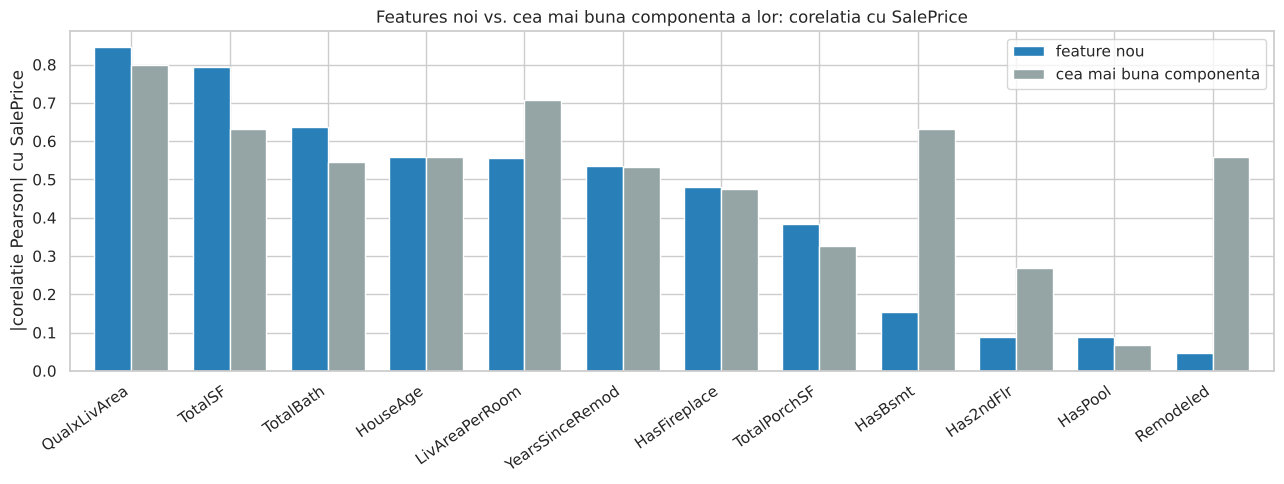

In [8]:
components = {
    "TotalSF": ["Total Bsmt SF", "1st Flr SF", "2nd Flr SF"],
    "HouseAge": ["Year Built", "Yr Sold"],
    "YearsSinceRemod": ["Year Remod/Add", "Yr Sold"],
    "Remodeled": ["Year Remod/Add", "Year Built"],
    "TotalBath": ["Full Bath", "Half Bath", "Bsmt Full Bath", "Bsmt Half Bath"],
    "TotalPorchSF": ["Wood Deck SF", "Open Porch SF", "Enclosed Porch", "3Ssn Porch", "Screen Porch"],
    "HasPool": ["Pool Area"],
    "HasFireplace": ["Fireplaces"],
    "Has2ndFlr": ["2nd Flr SF"],
    "HasBsmt": ["Total Bsmt SF"],
    "QualxLivArea": ["Overall Qual", "Gr Liv Area"],
    "LivAreaPerRoom": ["Gr Liv Area", "TotRms AbvGrd"],
}

rows = []
for f, comps in components.items():
    comp_corr = df_fe[comps].corrwith(df_fe["SalePrice"]).abs()
    rows.append({
        "feature_nou": f,
        "r_SalePrice": df_fe[f].corr(df_fe["SalePrice"]),
        "r_logSalePrice": df_fe[f].corr(df_fe["SalePrice_log"]),
        "cea_mai_buna_componenta": comp_corr.idxmax(),
        "r_componenta": df_fe[comp_corr.idxmax()].corr(df_fe["SalePrice"]),
    })
evidence = pd.DataFrame(rows).set_index("feature_nou")
evidence["castig_abs_r"] = evidence["r_SalePrice"].abs() - evidence["r_componenta"].abs()
print(evidence.round(3).to_string())

# Grafic: |r| feature nou vs |r| cea mai buna componenta
plot_df = evidence[["r_SalePrice", "r_componenta"]].abs().sort_values("r_SalePrice", ascending=False)
ax = plot_df.plot(kind="bar", figsize=(13, 5), color=["#2980b9", "#95a5a6"], width=0.75)
ax.set_ylabel("|corelatie Pearson| cu SalePrice")
ax.set_xlabel("")
ax.set_title("Features noi vs. cea mai buna componenta a lor: corelatia cu SalePrice")
ax.legend(["feature nou", "cea mai buna componenta"])
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

### Justificari si concluzii - feature engineering

*(schita cu valorile reale din rulare - de rescris de Carmen cu cuvintele ei)*

**Features care aduc castig clar** (corelatie cu pretul mai mare decat orice componenta a lor):
- `QualxLivArea` (r = 0.85): devine **cel mai puternic predictor individual din tot setul**, peste `Overall Qual` (0.80) si
  `Gr Liv Area` (0.71) - confirma interactiunea calitate x marime vazuta in scatter plots: metrii patrati valoreaza mai mult
  intr-o casa de calitate.
- `TotalSF` (r = 0.79 fata de 0.63 pentru `Total Bsmt SF`, cea mai buna componenta): suprafata totala bate fiecare nivel
  luat separat; pentru un cumparator conteaza spatiul total, nu cum e impartit pe etaje.
- `TotalBath` (0.64 fata de 0.55 pentru `Full Bath`): numarul total de bai, cu jumatatile numarate ca 0.5, este mai
  informativ decat orice coloana de bai luata singura.
- `TotalPorchSF` (0.38 fata de 0.33): castig modest, dar cinci coloane rare devin una singura, mai usor de interpretat.

**Features care nu cresc corelatia, dar sunt mai bune ca forma:**
- `HouseAge` (|r| = 0.56, identic cu `Year Built`): aceeasi informatie, dar exprimata relativ la momentul vanzarii, deci
  interpretabila direct ("o casa cu 10 ani mai veche costa cu X mai putin") si corecta pentru case vandute in ani diferiti.
  Cu `log(SalePrice)` corelatia creste la 0.62. Observatie: 1 casa avea varsta negativa si 3 renovare "in viitor" - vanzari
  partiale inainte de finalizare (`Partial`), am fixat valorile la 0.
- `YearsSinceRemod` (0.54): la fel, versiunea relativa a lui `Year Remod/Add`.
- `LivAreaPerRoom` (0.56): camere spatioase = casa mai scumpa, independent de numarul lor.

**Features slabe, pastrate doar ca indicatori pentru modele neliniare (sau de eliminat):**
- `HasFireplace` (0.48) nu aduce nimic peste `Fireplaces`; `Has2ndFlr` (0.09) si `HasBsmt` (0.15) sunt **mai slabe** decat
  suprafetele din care provin; `Remodeled` (-0.05) nu conteaza; `HasPool` (0.09) - doar 13 case au piscina, prea putine
  ca sa invatam ceva din ele.

**Atentie la multicoliniaritate.** `TotalSF` este o combinatie liniara exacta a componentelor sale, iar `QualxLivArea` este
foarte puternic corelat cu `Gr Liv Area` (r = 0.92) si `Overall Qual` (0.81). Intr-o regresie liniara nu trebuie incluse
simultan feature-ul compus si toate componentele lui (coeficienti instabili, greu de interpretat). Recomandare pentru L2:
`TotalSF` **in loc de** `1st Flr SF` + `2nd Flr SF` + `Total Bsmt SF`, `HouseAge` **in loc de** `Year Built`, `TotalBath`
**in loc de** cele 4 coloane de bai; modelele de tip arbore (Random Forest, Gradient Boosting) nu au aceasta problema si pot
primi toate coloanele.

## Perechi de features cu relatie liniara (input pentru partea Bonus)

Din heatmap si scatter plots reies urmatoarele perechi candidate pentru regresia liniara din Bonus (persoana C):

| Perechea | r (Pearson) | Comentariu |
|---|---|---|
| `Gr Liv Area` - `SalePrice` | 0.71 | relatie reala, cauzala: spatiu mai mult -> pret mai mare; cea mai naturala pentru regresie |
| `Overall Qual` - `SalePrice` | 0.80 | relatie reala, dar usor neliniara (pretul creste accelerat la calitate 8-10) |
| `TotalSF` - `SalePrice` | 0.79 | feature-ul nostru; alternativa mai buna la `Gr Liv Area` |
| `Garage Cars` - `Garage Area` | 0.89 | aproape tautologica: masoara acelasi lucru in unitati diferite |
| `Total Bsmt SF` - `1st Flr SF` | 0.80 | structurala: subsolul are de obicei amprenta parterului |
| `Year Built` - `Garage Yr Blt` | 0.86 | corelatie **fara cauzalitate directa** (cauza comuna: anul constructiei) - exemplu pentru discutia despre spurious correlations |

In [9]:
candidate_pairs = [("Gr Liv Area", "SalePrice"), ("Overall Qual", "SalePrice"), ("TotalSF", "SalePrice"),
                   ("Garage Cars", "Garage Area"), ("Total Bsmt SF", "1st Flr SF"), ("Year Built", "Garage Yr Blt"),
                   ("Gr Liv Area", "TotRms AbvGrd")]
for a, b in candidate_pairs:
    print(f"{a:>16} - {b:<16} r = {df_fe[a].corr(df_fe[b]):.3f}")

     Gr Liv Area - SalePrice        r = 0.707
    Overall Qual - SalePrice        r = 0.799
         TotalSF - SalePrice        r = 0.793
     Garage Cars - Garage Area      r = 0.890
   Total Bsmt SF - 1st Flr SF       r = 0.800
      Year Built - Garage Yr Blt    r = 0.861
     Gr Liv Area - TotRms AbvGrd    r = 0.808


In [10]:
# Salvam datasetul imbogatit pentru etapele urmatoare (L2 predictie, L3 clustering).
# Fisierele *.csv sunt in .gitignore, deci nu ajunge pe GitHub - fiecare il regenereaza ruland notebook-ul.
df_fe.to_csv("df_fe.csv", index=False)
print("Salvat: df_fe.csv", df_fe.shape)
print("Features noi adaugate:", new_features, "+ SalePrice_log (tinta transformata, nu feature)")

Salvat: df_fe.csv (2930, 96)
Features noi adaugate: ['TotalSF', 'HouseAge', 'YearsSinceRemod', 'Remodeled', 'TotalBath', 'TotalPorchSF', 'HasPool', 'HasFireplace', 'Has2ndFlr', 'HasBsmt', 'QualxLivArea', 'LivAreaPerRoom'] + SalePrice_log (tinta transformata, nu feature)


## Concluzii (Etapa 2 - partea B)

*(de completat de Carmen - 4-6 propozitii: ce am aflat despre relatiile dintre features, ce features noi recomandam pentru
modelul din L2 si ce ramane de clarificat in echipa - de ex. tratarea observatiilor cu Gr Liv Area > 4000)*